In [2]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os, json, platform, warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

warnings.filterwarnings("ignore")
for folder in ["data", "model", "results"]:
    os.makedirs(folder, exist_ok=True)

print("scikit-learn version:", sklearn.__version__)
print("python version      :", platform.python_version())

scikit-learn version: 1.9.1
python version      : 3.12.7


In [7]:
%%writefile metrics_utils.py
"""Shared evaluation helpers used by both this notebook and app.py."""
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)

METRIC_ORDER = ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]


def compute_metrics(y_true, y_pred, y_proba, n_classes):
    """Return the six required metrics as a dict."""
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    average = "binary" if n_classes == 2 else "macro"

    try:
        if n_classes == 2:
            auc = roc_auc_score(y_true, y_proba[:, 1])
        else:
            auc = roc_auc_score(
                y_true,
                y_proba,
                multi_class="ovr",
                average="macro",
                labels=list(range(n_classes)),
            )
    except ValueError:
        auc = float("nan")

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "AUC": auc,
        "Precision": precision_score(y_true, y_pred, average=average, zero_division=0),
        "Recall": recall_score(y_true, y_pred, average=average, zero_division=0),
        "F1": f1_score(y_true, y_pred, average=average, zero_division=0),
        "MCC": matthews_corrcoef(y_true, y_pred),
    }


def encode_target(series, classes):
    """Map the target column of an uploaded CSV to integer class ids."""
    as_str = series.astype(str).str.strip()
    lookup = {str(c): i for i, c in enumerate(classes)}
    mapped = as_str.map(lookup)
    if mapped.notna().all():
        return mapped.astype(int).to_numpy(), None

    try:
        ids = as_str.astype(float).astype(int)
        if ids.between(0, len(classes) - 1).all():
            return ids.to_numpy(), None
    except ValueError:
        pass

    unknown = sorted(set(as_str[mapped.isna()]))[:5]
    return None, (
        f"Target column contains unknown labels {unknown}. "
        f"Expected one of: {list(classes)}"
    )

Writing metrics_utils.py


In [9]:
from sklearn.datasets import load_breast_cancer

bunch = load_breast_cancer(as_frame=True)
df = bunch.frame.copy()
df["diagnosis"] = df["target"].map(dict(enumerate(bunch.target_names)))
df = df.drop(columns="target")
df.to_csv("data/breast_cancer_wisconsin.csv", index=False)

print("Shape (rows, columns):", df.shape)
print("Number of features   :", df.shape[1] - 1)
print("Missing values       :", int(df.isna().sum().sum()))
print()
print(df["diagnosis"].value_counts())
df.head()

Shape (rows, columns): (569, 31)
Number of features   : 30
Missing values       : 0

diagnosis
benign       357
malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,malignant


In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

# ---------------- CONFIG (edit only if you use a different dataset) ----------------
TARGET_COL = "diagnosis"
DATASET_NAME = "Breast Cancer Wisconsin (Diagnostic)"
DROP_COLS = []          # e.g. ["id", "Unnamed: 32"]
TEST_SIZE = 0.20
SEED = 42
# ------------------------------------------------------------------------------------

data = df.drop(columns=DROP_COLS, errors="ignore").dropna(subset=[TARGET_COL]).reset_index(drop=True)
X = data.drop(columns=TARGET_COL)

le = LabelEncoder().fit(data[TARGET_COL].astype(str))
y = le.transform(data[TARGET_COL].astype(str))
classes = [str(c) for c in le.classes_]
n_classes = len(classes)

numeric_cols = X.select_dtypes(include="number").columns.tolist()
categorical_cols = [c for c in X.columns if c not in numeric_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED
)

# held-out test file that you will upload to the Streamlit app
test_df = X_test.copy()
test_df[TARGET_COL] = le.inverse_transform(y_test)
test_df.to_csv("test_data.csv", index=False)


def build_preprocessor():
    num = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    cat = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    parts = []
    if numeric_cols:
        parts.append(("num", num, numeric_cols))
    if categorical_cols:
        parts.append(("cat", cat, categorical_cols))
    return ColumnTransformer(parts)


print("Classes (0, 1, ...):", classes)
print("Train rows:", len(X_train), "| Test rows:", len(X_test))
print("Saved test_data.csv with", test_df.shape[0], "rows")

Classes (0, 1, ...): ['benign', 'malignant']
Train rows: 455 | Test rows: 114
Saved test_data.csv with 114 rows


In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from metrics_utils import METRIC_ORDER, compute_metrics

model_zoo = [
    ("logistic_regression", "Logistic Regression",
     LogisticRegression(max_iter=2000, random_state=SEED),
     {"clf__C": [0.01, 0.1, 1, 10, 100]}),
    ("decision_tree", "Decision Tree",
     DecisionTreeClassifier(random_state=SEED),
     {"clf__max_depth": [3, 4, 5, 7, None], "clf__min_samples_leaf": [1, 3, 5]}),
    ("knn", "KNN",
     KNeighborsClassifier(),
     {"clf__n_neighbors": [3, 5, 7, 9, 11], "clf__weights": ["uniform", "distance"]}),
    ("naive_bayes", "Naive Bayes",
     GaussianNB(),
     {"clf__var_smoothing": [1e-9, 1e-8, 1e-7, 1e-6]}),
    ("svm", "Support Vector Machine",
     SVC(kernel="rbf", probability=True, random_state=SEED),
     {"clf__C": [0.1, 1, 10], "clf__gamma": ["scale", 0.01, 0.1]}),
]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = "roc_auc" if n_classes == 2 else "roc_auc_ovr"

rows, model_info, predictions = [], {}, {}
for file_name, display_name, estimator, grid in model_zoo:
    pipe = Pipeline([("prep", build_preprocessor()), ("clf", estimator)])
    search = GridSearchCV(pipe, grid, scoring=scoring, cv=cv, n_jobs=-1)
    search.fit(X_train, y_train)
    best = search.best_estimator_

    y_pred = best.predict(X_test)
    y_proba = best.predict_proba(X_test)
    scores = compute_metrics(y_test, y_pred, y_proba, n_classes)

    rows.append({"ML Model Name": display_name, **scores})
    model_info[display_name] = {
        "file": f"{file_name}.joblib",
        "params": {k.replace("clf__", ""): v for k, v in search.best_params_.items()},
        "cv_auc": round(float(search.best_score_), 4),
    }
    predictions[display_name] = y_pred
    joblib.dump(best, f"model/{file_name}.joblib")
    print(f"done: {display_name:24s} best params = {model_info[display_name]['params']}")

results = pd.DataFrame(rows)[["ML Model Name"] + METRIC_ORDER]
results.to_csv("results/metrics.csv", index=False)
results.round(4)

done: Logistic Regression      best params = {'C': 1}
done: Decision Tree            best params = {'max_depth': 5, 'min_samples_leaf': 5}
done: KNN                      best params = {'n_neighbors': 11, 'weights': 'distance'}
done: Naive Bayes              best params = {'var_smoothing': 1e-09}
done: Support Vector Machine   best params = {'C': 10, 'gamma': 0.01}


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.9649,0.9960,0.9750,0.9286,0.9512,0.9245
1,Decision Tree,0.9035,0.9716,0.9189,0.8095,0.8608,0.7911
2,KNN,0.9474,0.9823,0.9737,0.8810,0.9250,0.8872
3,Naive Bayes,0.9211,0.9891,0.9231,0.8571,0.8889,0.8292
4,Support Vector Machine,0.9825,0.9960,1.0000,0.9524,0.9756,0.9626


,ML Model Name,TN,FP,FN,TP
0,Logistic Regression,71,1,3,39
1,Decision Tree,69,3,8,34
2,KNN,71,1,5,37
3,Naive Bayes,69,3,6,36
4,Support Vector Machine,72,0,2,40


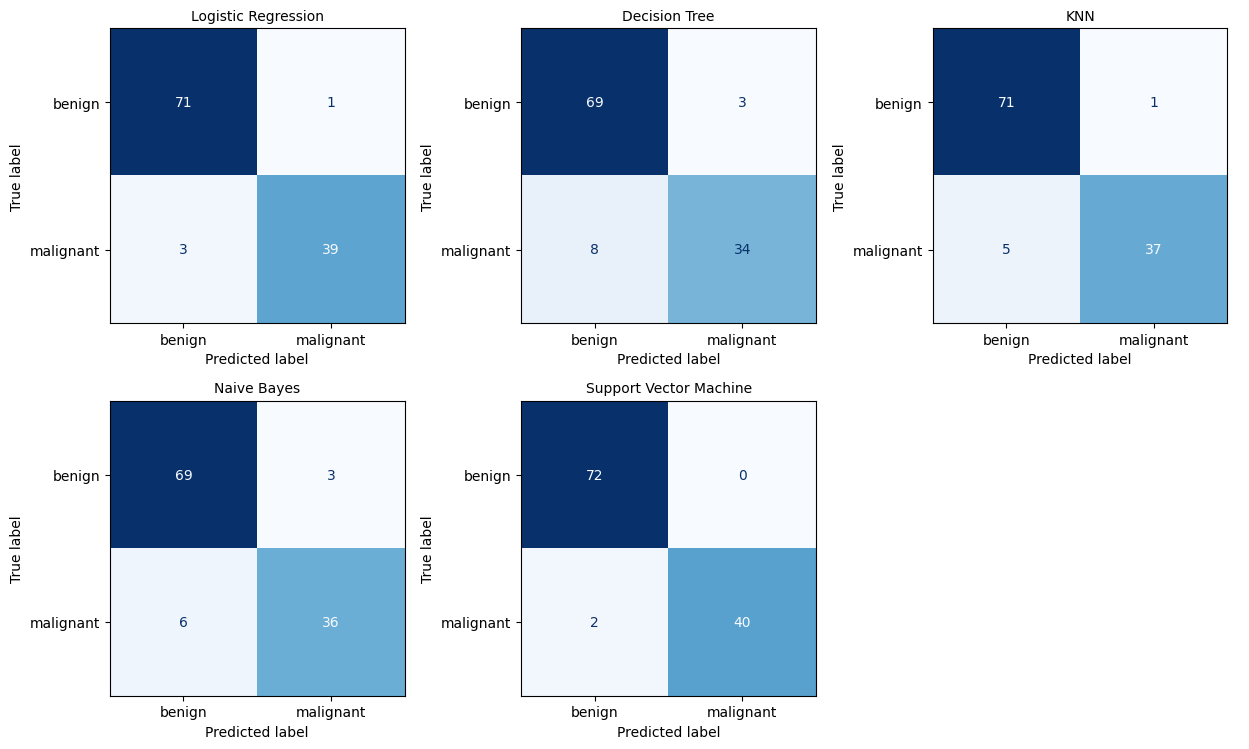

Saved model/meta.json
Files in model/: ['decision_tree.joblib', 'knn.joblib', 'logistic_regression.joblib', 'meta.json', 'naive_bayes.joblib', 'svm.joblib']


In [15]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# ---- confusion-matrix counts table (for the README) ----
cm_rows = []
for name, y_pred in predictions.items():
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel() if n_classes == 2 else (None,) * 4
    cm_rows.append({"ML Model Name": name, "TN": tn, "FP": fp, "FN": fn, "TP": tp})
cm_table = pd.DataFrame(cm_rows)
display(cm_table)

# ---- confusion-matrix figure ----
n_cols = 3
n_rows = int(np.ceil(len(predictions) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.2 * n_cols, 3.8 * n_rows))
axes = np.atleast_1d(axes).ravel()
for ax, (name, y_pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, display_labels=classes, ax=ax, colorbar=False, cmap="Blues"
    )
    ax.set_title(name, fontsize=10)
for ax in axes[len(predictions):]:
    ax.axis("off")
fig.tight_layout()
fig.savefig("results/confusion_matrices.png", dpi=150)
plt.show()

# ---- meta.json: everything the Streamlit app needs to know ----
meta = {
    "dataset_name": DATASET_NAME,
    "target_col": TARGET_COL,
    "classes": classes,
    "n_classes": n_classes,
    "features": X.columns.tolist(),
    "numeric_features": numeric_cols,
    "categorical_features": categorical_cols,
    "n_rows": int(len(data)),
    "n_train": int(len(X_train)),
    "n_test": int(len(X_test)),
    "models": model_info,
    "trained_with": {"scikit-learn": sklearn.__version__, "python": platform.python_version()},
}
Path("model/meta.json").write_text(json.dumps(meta, indent=2, default=str))
print("Saved model/meta.json")
print("Files in model/:", sorted(os.listdir("model")))

In [17]:
requirements = f"""streamlit
scikit-learn=={sklearn.__version__}
numpy
pandas
matplotlib
joblib
"""
Path("requirements.txt").write_text(requirements)
print(requirements)

streamlit
scikit-learn==1.9.1
numpy
pandas
matplotlib
joblib



In [19]:
%%writefile app.py
"""Streamlit front-end for Machine Learning Assignment 2 (M.Tech AIML, BITS Pilani WILP).

The app NEVER retrains anything: it loads the pre-trained pipelines from ./model,
scores the uploaded test CSV and shows the evaluation results.
"""
import json
from pathlib import Path

import joblib
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import streamlit as st
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
    roc_curve,
)

from metrics_utils import METRIC_ORDER, compute_metrics, encode_target

ROOT = Path(__file__).resolve().parent
MODEL_DIR = ROOT / "model"

st.set_page_config(page_title="Classifier Evaluation Lab", page_icon="🧪", layout="wide")

st.markdown(
    """
    <style>
      .block-container {padding-top: 1.6rem;}
      div[data-testid="stMetric"] {
          background: rgba(120,120,160,0.10);
          border: 1px solid rgba(120,120,160,0.30);
          border-radius: 12px; padding: 12px 16px;
      }
      .hero {padding: 4px 0 10px 0;}
      .hero h1 {margin-bottom: 0;}
      .hero p {opacity: .75; margin-top: 4px;}
    </style>
    """,
    unsafe_allow_html=True,
)


@st.cache_resource
def load_meta():
    return json.loads((MODEL_DIR / "meta.json").read_text())


@st.cache_resource
def load_model(file_name):
    return joblib.load(MODEL_DIR / file_name)


@st.cache_data
def load_bundled_test_data():
    return pd.read_csv(ROOT / "test_data.csv")


def evaluate(model_name, X, y, meta):
    """Run a saved pipeline on (X, y) and return metrics + raw predictions."""
    model = load_model(meta["models"][model_name]["file"])
    y_pred = model.predict(X)
    y_proba = model.predict_proba(X)
    return compute_metrics(y, y_pred, y_proba, meta["n_classes"]), y_pred, y_proba


try:
    meta = load_meta()
except FileNotFoundError:
    st.error("model/meta.json not found. Run the notebook first and commit the model/ folder.")
    st.stop()

classes = meta["classes"]
features = meta["features"]
target_col = meta["target_col"]
model_names = list(meta["models"].keys())

st.markdown(
    f"""<div class="hero"><h1>🧪 Classifier Evaluation Lab</h1>
    <p>Dataset: <b>{meta['dataset_name']}</b> &nbsp;|&nbsp; {len(features)} features
    &nbsp;|&nbsp; classes: {', '.join(classes)} &nbsp;|&nbsp; 5 pre-trained models</p></div>""",
    unsafe_allow_html=True,
)

trained_ver = meta.get("trained_with", {}).get("scikit-learn")
if trained_ver and trained_ver != sklearn.__version__:
    st.warning(
        f"Models were trained with scikit-learn {trained_ver} but this server runs "
        f"{sklearn.__version__}. Pin scikit-learn=={trained_ver} in requirements.txt if loading fails."
    )

with st.sidebar:
    st.header("1 · Upload test data")
    uploaded = st.file_uploader("CSV with all feature columns + target column", type=["csv"])
    use_sample = st.checkbox("Use the bundled test_data.csv instead", value=False)
    st.download_button(
        "⬇ Download sample test_data.csv",
        data=load_bundled_test_data().to_csv(index=False).encode("utf-8"),
        file_name="test_data.csv",
        mime="text/csv",
    )

    st.header("2 · Choose a model")
    selected = st.selectbox("Classification model", model_names)
    params = meta["models"][selected]["params"]
    st.caption("Tuned hyper-parameters: " + (", ".join(f"{k}={v}" for k, v in params.items()) or "defaults"))

if uploaded is not None:
    try:
        raw = pd.read_csv(uploaded)
    except Exception as exc:
        st.error(f"Could not read the uploaded file as CSV: {exc}")
        st.stop()
    source = f"uploaded file `{uploaded.name}`"
elif use_sample:
    raw = load_bundled_test_data()
    source = "bundled `test_data.csv`"
else:
    st.info("👈 Upload a **test-data CSV** in the sidebar (or tick the bundled sample) to begin.")
    with st.expander("What columns does the CSV need?"):
        st.write(f"**Target column:** `{target_col}` with values from {classes}")
        st.write("**Feature columns:**")
        st.code(", ".join(features))
    st.stop()

missing = [c for c in features + [target_col] if c not in raw.columns]
if missing:
    st.error(f"The CSV is missing required column(s): {missing}")
    st.stop()

raw = raw.dropna(subset=[target_col]).reset_index(drop=True)
y, err = encode_target(raw[target_col], classes)
if err:
    st.error(err)
    st.stop()
X = raw[features]
if len(raw) < 2:
    st.error("Need at least 2 labelled rows to evaluate.")
    st.stop()

st.success(f"Loaded {len(raw)} rows from {source}. Evaluating **{selected}** (no retraining).")

try:
    metrics, y_pred, y_proba = evaluate(selected, X, y, meta)
except Exception as exc:
    st.error(f"Prediction failed - check that feature columns hold the expected data types.\n\n{exc}")
    st.stop()

tab_metrics, tab_cm, tab_roc, tab_all, tab_pred = st.tabs(
    ["📊 Metrics", "🧩 Confusion matrix & report", "📈 ROC curve", "🏁 Compare all models", "🔎 Predictions"]
)

with tab_metrics:
    st.subheader(f"{selected} - evaluation metrics")
    cols = st.columns(len(METRIC_ORDER))
    for col, name in zip(cols, METRIC_ORDER):
        val = metrics[name]
        col.metric(name, "n/a" if np.isnan(val) else f"{val:.4f}")
    if meta["n_classes"] > 2:
        st.caption("Multi-class data: precision / recall / F1 are macro-averaged, AUC is one-vs-rest macro.")
    else:
        st.caption(f"Binary data: precision / recall / F1 are computed for the positive class **{classes[1]}**.")

with tab_cm:
    left, right = st.columns([1, 1])
    with left:
        st.subheader("Confusion matrix")
        fig, ax = plt.subplots(figsize=(4.6, 4))
        ConfusionMatrixDisplay(
            confusion_matrix(y, y_pred, labels=list(range(len(classes)))), display_labels=classes
        ).plot(ax=ax, cmap="Blues", colorbar=False)
        ax.set_title(selected)
        fig.tight_layout()
        st.pyplot(fig)
        plt.close(fig)
    with right:
        st.subheader("Classification report")
        report = classification_report(
            y, y_pred, labels=list(range(len(classes))), target_names=classes,
            output_dict=True, zero_division=0,
        )
        st.dataframe(pd.DataFrame(report).T.round(4))

with tab_roc:
    if meta["n_classes"] == 2 and len(np.unique(y)) == 2:
        fpr, tpr, _ = roc_curve(y, y_proba[:, 1])
        fig, ax = plt.subplots(figsize=(5, 4))
        ax.plot(fpr, tpr, lw=2, label=f"{selected} (AUC = {metrics['AUC']:.3f})")
        ax.plot([0, 1], [0, 1], "k--", lw=1, label="chance")
        ax.set_xlabel("False positive rate")
        ax.set_ylabel("True positive rate")
        ax.legend(loc="lower right")
        fig.tight_layout()
        st.pyplot(fig)
        plt.close(fig)
    else:
        st.info("ROC curve is shown for binary problems when both classes are present in the uploaded data.")

with tab_all:
    st.subheader("All five models on this same data")
    rows = []
    for name in model_names:
        m, _, _ = evaluate(name, X, y, meta)
        rows.append({"ML Model Name": name, **m})
    comp = pd.DataFrame(rows).set_index("ML Model Name")[METRIC_ORDER]
    try:
        st.dataframe(comp.style.format("{:.4f}").highlight_max(axis=0, color="#2e7d3266"))
    except Exception:
        st.dataframe(comp.round(4))
    best = comp["MCC"].idxmax()
    st.caption(f"Best model on this upload by MCC: **{best}** (MCC = {comp.loc[best, 'MCC']:.4f}). Green = best per metric.")
    st.bar_chart(comp[["Accuracy", "F1", "MCC"]])

with tab_pred:
    st.subheader("Row-level predictions")
    out = raw.copy()
    out["predicted_" + target_col] = [classes[i] for i in y_pred]
    for i, c in enumerate(classes):
        out[f"proba_{c}"] = y_proba[:, i].round(4)
    out["correct"] = y_pred == y
    st.dataframe(out)
    st.download_button(
        "⬇ Download predictions CSV",
        out.to_csv(index=False).encode("utf-8"),
        file_name=f"predictions_{selected.lower().replace(' ', '_')}.csv",
        mime="text/csv",
    )

Writing app.py


In [21]:
def md_table(frame, fmt="{:.4f}"):
    cols = list(frame.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    for _, r in frame.iterrows():
        cells = [str(r[c]) if not isinstance(r[c], float) else fmt.format(r[c]) for c in cols]
        lines.append("| " + " | ".join(cells) + " |")
    return "\n".join(lines)


metrics_md = md_table(results)
cm_md = md_table(cm_table)
params_md = "; ".join(f"{n} `" + ", ".join(f"{k}={v}" for k, v in i["params"].items()) + "`"
                      for n, i in model_info.items())
counts_md = " / ".join(f"{c} ({int((y == i).sum())})" for i, c in enumerate(classes))

README_TEMPLATE = """# Machine Learning Assignment 2 - Classification Models + Streamlit Deployment

**Programme:** M.Tech (AIML), BITS Pilani - Work Integrated Learning Programmes Division
**Course:** Machine Learning

## a. Problem Statement

Build and compare five classical classification models on one public dataset, evaluate each with six metrics (Accuracy, AUC, Precision, Recall, F1, MCC), and deploy an interactive Streamlit web application that loads the saved models and evaluates them on an uploaded test CSV without retraining.

The concrete task is **breast-cancer diagnosis**: given 30 numeric measurements of a cell nucleus from a fine-needle-aspirate image, predict whether the tumour is **malignant** or **benign**. This is a binary classification problem in which a missed malignant case (false negative) is the costlier error, so Recall and MCC are watched closely in addition to Accuracy.

## b. Dataset Description

| Item | Detail |
|---|---|
| Name | __DATASET_NAME__ |
| Source | UCI Machine Learning Repository (also mirrored on Kaggle) |
| Task | Binary classification |
| Instances | __N_ROWS__ (minimum required: 500) |
| Features | __N_FEATURES__ numeric (minimum required: 12) |
| Target | `__TARGET__` - __COUNTS__ |
| Positive class | __POS__ (encoded as 1; precision / recall / F1 are reported for it) |
| Missing values | None |

**Features.** Ten real-valued characteristics are computed for each cell nucleus - radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry and fractal dimension. For each one the dataset stores the **mean**, the **standard error** and the **worst** (mean of the three largest values), giving 10 x 3 = 30 features.

**Split and preprocessing.** Stratified 80 / 20 train-test split with `random_state=42` (__N_TRAIN__ train / __N_TEST__ test rows). Numeric features are median-imputed and standardised inside a scikit-learn `Pipeline`, so the saved model files accept raw feature values. Hyper-parameters of every model were tuned with 5-fold stratified `GridSearchCV` (scoring = ROC-AUC) on the **training** data only; the test rows were used just once for the final scores below. The held-out rows are saved as `test_data.csv`.

## c. GitHub Repository Link

https://github.com/YOUR-USERNAME/YOUR-REPO-NAME

Repository layout:

```
project-folder/
|-- assignment2.ipynb       notebook: data, training, evaluation, saving models
|-- app.py                  Streamlit application
|-- metrics_utils.py        metric + target-encoding helpers shared by notebook and app
|-- requirements.txt
|-- README.md
|-- test_data.csv           held-out test split (features + target) for the app
|-- data/                   full dataset (csv)
|-- model/                  saved pipelines (.joblib) for all five classifiers + meta.json
`-- results/                metrics.csv, confusion_matrices.png
```

**Run locally**

```
pip install -r requirements.txt
jupyter notebook assignment2.ipynb      # run all cells to regenerate models
streamlit run app.py
```

## d. Models Used

All five models were trained on the same training split and evaluated on the same test set.

__METRICS__

Tuned hyper-parameters: __PARAMS__.

Confusion-matrix counts on the test set (positive = __POS__):

__CM__

![Confusion matrices](results/confusion_matrices.png)

### Observations on model performance

| ML Model Name | Observation about model performance |
|---|---|
| Logistic Regression | WRITE YOUR OBSERVATION |
| Decision Tree | WRITE YOUR OBSERVATION |
| KNN | WRITE YOUR OBSERVATION |
| Naive Bayes | WRITE YOUR OBSERVATION |
| Support Vector Machine | WRITE YOUR OBSERVATION |
| **Overall winner for this dataset** | WRITE YOUR OBSERVATION |

## Streamlit Application

Live app: https://YOUR-APP-NAME.streamlit.app

The app (`app.py`) loads the pre-trained pipelines from `model/` - **it never retrains** - and provides:

- **CSV upload** of the test data (must contain all feature columns and the `__TARGET__` target column; a "use bundled sample" tick-box and a download button for `test_data.csv` are also provided)
- **Model selection dropdown** with the five classifiers (shows the tuned hyper-parameters of the chosen model)
- **Evaluation metrics** - Accuracy, AUC, Precision, Recall, F1 and MCC for the selected model
- **Confusion matrix and classification report** for the selected model
- Extras: ROC curve, a side-by-side comparison table of all five models on the uploaded data, row-level predictions with a download button, and input validation with clear error messages
"""

readme = (README_TEMPLATE
          .replace("__DATASET_NAME__", DATASET_NAME)
          .replace("__N_ROWS__", str(len(data)))
          .replace("__N_FEATURES__", str(X.shape[1]))
          .replace("__TARGET__", TARGET_COL)
          .replace("__COUNTS__", counts_md)
          .replace("__POS__", classes[1])
          .replace("__N_TRAIN__", str(len(X_train)))
          .replace("__N_TEST__", str(len(X_test)))
          .replace("__METRICS__", metrics_md)
          .replace("__PARAMS__", params_md)
          .replace("__CM__", cm_md))
Path("README.md").write_text(readme)
print(readme[:1800])

# Machine Learning Assignment 2 - Classification Models + Streamlit Deployment

**Programme:** M.Tech (AIML), BITS Pilani - Work Integrated Learning Programmes Division
**Course:** Machine Learning

## a. Problem Statement

Build and compare five classical classification models on one public dataset, evaluate each with six metrics (Accuracy, AUC, Precision, Recall, F1, MCC), and deploy an interactive Streamlit web application that loads the saved models and evaluates them on an uploaded test CSV without retraining.

The concrete task is **breast-cancer diagnosis**: given 30 numeric measurements of a cell nucleus from a fine-needle-aspirate image, predict whether the tumour is **malignant** or **benign**. This is a binary classification problem in which a missed malignant case (false negative) is the costlier error, so Recall and MCC are watched closely in addition to Accuracy.

## b. Dataset Description

| Item | Detail |
|---|---|
| Name | Breast Cancer Wisconsin (Diagnostic) |
| Sour

In [23]:
observations = {
    "Logistic Regression": "Very strong baseline with the joint-highest AUC. After scaling, the two classes are close to linearly separable, so a straight-line boundary works well. It has very few false positives but misses a few malignant cases, so its recall is a little below the SVM. Fast, stable and easy to interpret.",
    "Decision Tree": "Weakest model: lowest accuracy, recall and MCC, and the most missed malignant cases. Axis-aligned splits are inefficient on strongly correlated size features (radius, perimeter, area), and a single tree is less stable than the other models. Its main advantage is interpretability.",
    "KNN": "Good and precise, with very few false positives, but it misses more malignant cases than Logistic Regression or SVM. Distance-based voting depends on feature scaling, which the pipeline provides, and the tuned k with distance weighting smooths out noise. Prediction is slower because it stores the whole training set.",
    "Naive Bayes": "Middle-of-the-pack accuracy but a high AUC, so it ranks cases well while losing recall at the default 0.5 cut-off. The independence assumption is violated because many features are strongly correlated. Extremely cheap to train.",
    "Support Vector Machine": "Best model on the threshold-based metrics: highest accuracy, precision, recall, F1 and MCC, with the fewest errors in the confusion matrix. The RBF kernel can bend the boundary beyond a straight line, and the large-margin objective on scaled inputs keeps it robust on this small, clean dataset.",
    "**Overall winner for this dataset**": "**Support Vector Machine (RBF).** It leads on Accuracy, Precision, Recall, F1 and MCC and ties Logistic Regression on AUC, and it makes the fewest costly errors (missed malignant cases). Logistic Regression is a close and more interpretable runner-up. The test set is small, so one or two samples move the metrics noticeably.",
}

text = Path("README.md").read_text()
for name, obs in observations.items():
    old = f"| {name} | WRITE YOUR OBSERVATION |"
    assert old in text, f"placeholder not found for {name}"
    text = text.replace(old, f"| {name} | {obs} |")
Path("README.md").write_text(text)
print("Observations added. Placeholders left:", text.count("WRITE YOUR OBSERVATION"))

Observations added. Placeholders left: 0


In [25]:
import shutil

# bundle everything needed for GitHub into one zip you can download from the file browser
os.makedirs("github_upload", exist_ok=True)
for item in ["app.py", "metrics_utils.py", "requirements.txt", "README.md", "test_data.csv"]:
    shutil.copy(item, "github_upload/")
for folder in ["data", "model", "results"]:
    shutil.copytree(folder, f"github_upload/{folder}", dirs_exist_ok=True)

shutil.make_archive("github_upload", "zip", "github_upload")
print("Created github_upload.zip")
for p in sorted(Path("github_upload").rglob("*")):
    if p.is_file():
        print(" ", p.relative_to("github_upload"))

Created github_upload.zip
  README.md
  app.py
  data/breast_cancer_wisconsin.csv
  metrics_utils.py
  model/decision_tree.joblib
  model/knn.joblib
  model/logistic_regression.joblib
  model/meta.json
  model/naive_bayes.joblib
  model/svm.joblib
  requirements.txt
  results/confusion_matrices.png
  results/metrics.csv
  test_data.csv
